# Módulo 3 — Diferenciação e raízes unitárias

> **Controle bibliográfico — revisão de 21/11/2026 (M3S2).** Classificação: **parcial**.
> **Obra conferida:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos Lineares Univariados*, v. 1, 3ª ed., Blucher, 2018. Localização pertinente: **§1.4, pp. 5–6; §5.1, pp. 111–112; cap. 10 no sumário**.
> **Escopo:** Álgebra geral de diferenças, mas tratamento avançado sazonal não está no PDF parcial.
> A cópia enviada nesta revisão tem **150 páginas PDF** (até a p. impressa 131). Referências além desse limite, mesmo indicadas pelo sumário ou por edições integrais consultadas anteriormente, **não foram reconferidas nesta cópia**. Exemplos, demonstrações estendidas, gráficos e Python não são automaticamente atribuídos aos autores.


## Seção 2 — Diferenciação sazonal e combinação de operadores

**Estado editorial:** versão inicial completa para revisão. **Integração:** definições e cálculos, exemplos manuais, código Python, gráficos, interpretação e exercícios. **Pré-requisitos:** sazonalidade de período conhecido e índices temporais (Módulo 2); operador de atraso e diferenças simples (Seção 1 do Módulo 3).

**Base bibliográfica:** a notação da diferença e do operador de atraso foi conferida em Morettin e Toloi, *Análise de Séries Temporais: Modelos Lineares Univariados*, v. 1, 3ª ed., §1.4, p. 6, e §5.3.1, p. 143. A diferença sazonal é abordada no mapeamento das aulas, em “Aplicação de Diferenças”, e o assunto dos modelos sazonais aparece no sumário do mesmo livro (cap. 10, a partir da p. 245). **Nesta seção, as deduções específicas das diferenças sazonais, os exemplos e o código são complementações didáticas próprias**; não são atribuídas a uma página do capítulo 10 ainda não conferida em detalhe.

### Objetivos de aprendizagem

Ao terminar, você deverá saber: (i) escrever e interpretar a diferença sazonal de período $s$; (ii) distinguir a operação sazonal da diferença simples; (iii) deduzir a composição $(1-B)(1-B^s)$; (iv) explicar as perdas de observações e como as operações são alinhadas; (v) identificar condições sob as quais a diferença sazonal elimina um padrão fixo; (vi) implementar e interpretar as transformações no Python sem confundir ausência de sazonalidade visual com estacionariedade estatística.

### 1. Motivação: comparar o mesmo período em ciclos diferentes

Considere dados trimestrais. Uma observação do primeiro trimestre costuma ser mais comparável à de outro primeiro trimestre do que à do trimestre imediatamente anterior. Se a série possui um componente sazonal fixo com período $s=4$, temos:

$$
S_{t+4}=S_t.
$$

A primeira diferença $Z_t-Z_{t-1}$ compara trimestres consecutivos; ela **não** elimina necessariamente uma sazonalidade de quatro trimestres. Para comparar a mesma posição em ciclos consecutivos, precisamos de $Z_t-Z_{t-4}$.

Esse é o problema resolvido pela diferenciação sazonal.

### 2. Definição do operador de diferença sazonal

Seja $s\geq2$ um inteiro que representa o número de observações por ciclo. O operador de diferença sazonal de ordem um é:

$$
\boxed{\Delta_s=1-B^s.}
$$

Aplicando-o a $Z_t$:

$$
\boxed{\Delta_s Z_t=Z_t-Z_{t-s}.}
$$

Exemplos: para dados mensais com período anual, $s=12$, e a observação é comparada ao mesmo mês do ano anterior; para dados trimestrais anuais, $s=4$; para dados horários com periodicidade diária e amostragem regular, $s=24$.

**Atenção:** um período sazonal só pode ser interpretado assim quando os índices representam intervalos de observação coerentes. Falhas de registro e agregações desiguais podem invalidar a comparação por índice.

#### 2.1 Exemplo completo com números

Considere três anos de dados trimestrais, com 12 observações:

$$
(z_1,\ldots,z_{12})=(10,14,17,13,\;12,16,19,15,\;14,18,21,17).
$$

O modelo numérico é construído de forma que os valores do mesmo trimestre aumentem exatamente 2 unidades de um ano para o seguinte. Calculando a diferença sazonal $s=4$:

$$
\begin{aligned}
\Delta_4 z_5&=z_5-z_1=12-10=2,\\
\Delta_4 z_6&=z_6-z_2=16-14=2,\\
\Delta_4 z_7&=z_7-z_3=19-17=2,\\
\Delta_4 z_8&=z_8-z_4=15-13=2.
\end{aligned}
$$

Repetindo para os quatro instantes restantes, obtemos:

$$
(\Delta_4z_5,\ldots,\Delta_4z_{12})=(2,2,2,2,2,2,2,2).
$$

A sazonalidade fixa deixou de aparecer na sequência de diferenças; permanece uma variação de nível entre anos. Neste exemplo construído, a saída é constante porque **não há ruído**. Em uma série real, diferenças sazonais não serão necessariamente constantes.

| Observação | $z_t$ | $z_{t-4}$ | $\Delta_4z_t$ |
|---|---:|---:|---:|
| $t=5$ | 12 | 10 | 2 |
| $t=6$ | 16 | 14 | 2 |
| $t=7$ | 19 | 17 | 2 |
| $t=8$ | 15 | 13 | 2 |
| $t=9$ | 14 | 12 | 2 |
| $t=10$ | 18 | 16 | 2 |
| $t=11$ | 21 | 19 | 2 |
| $t=12$ | 17 | 15 | 2 |

A perda inicial é de **quatro valores**, porque $z_1,\ldots,z_4$ não possuem correspondentes observados quatro instantes antes.

### 3. O que acontece com o modelo aditivo?

Considere a série:

$$
Z_t=\alpha+\beta t+S_t+\varepsilon_t,
$$

com $S_t=S_{t-s}$. A diferença sazonal é:

$$
\begin{aligned}
\Delta_sZ_t
&=Z_t-Z_{t-s}\\
&=[\alpha+\beta t+S_t+\varepsilon_t]\\
&\quad-[\alpha+\beta(t-s)+S_{t-s}+\varepsilon_{t-s}]\\
&=\beta s+\varepsilon_t-\varepsilon_{t-s}.
\end{aligned}
$$

**Interpretação:** o efeito sazonal fixo se cancela, mas a tendência linear origina a constante $\beta s$. A transformação por diferença sazonal não “remove todos os componentes” do modelo: altera suas formas.

Se os erros são ruído branco com média zero, variância $\sigma^2$ e covariância nula para instantes distintos, então:

$$
E[\Delta_sZ_t]=\beta s,
$$

$$
\mathrm{Var}(\Delta_sZ_t)=2\sigma^2.
$$

Para uma defasagem sazonal $h=s$:

$$
\mathrm{Cov}(\Delta_sZ_t,\Delta_sZ_{t-s})=-\sigma^2.
$$

Para $h\neq0,\pm s$, a covariância é zero (sob as hipóteses declaradas). Portanto, a série diferenciada é fracamente estacionária nesse modelo, apesar de possuir correlação sazonal negativa na defasagem $s$. Essa estrutura mostra que **cancelar um componente determinístico pode introduzir dependência nos erros transformados**.

**Hipótese crucial:** se o padrão sazonal $S_t$ mudar de forma arbitrária a cada ciclo, a identidade $S_t=S_{t-s}$ falha e o cancelamento exato deixa de valer.

### 4. Diferença simples versus diferença sazonal

| Aspecto | Diferença simples | Diferença sazonal |
|---|---|---|
| Operador | $1-B$ | $1-B^s$ |
| Expressão | $Z_t-Z_{t-1}$ | $Z_t-Z_{t-s}$ |
| Comparação | Instantes consecutivos | Mesma posição em ciclos consecutivos |
| Perda inicial, em dados completos | 1 observação | $s$ observações |
| Efeito sobre uma tendência linear | $\beta$ | $s\beta$ |
| Cancela $S_t$ com $S_{t+s}=S_t$? | Não em geral | Sim |

**Não confundir:** aplicar quatro primeiras diferenças, $(1-B)^4$, é muito diferente de aplicar uma diferença sazonal trimestral, $(1-B^4)$. A primeira combina cinco observações adjacentes com coeficientes binomiais; a segunda subtrai apenas duas observações separadas por quatro instantes.

### 5. Combinação dos operadores $(1-B)(1-B^s)$

Algumas séries apresentam simultaneamente tendência e sazonalidade. Podemos combinar uma diferença simples e uma sazonal, sem assumir que isso seja sempre necessário. O operador combinado é:

$$
\boxed{\Delta\Delta_s=(1-B)(1-B^s).}
$$

Como os dois operadores são polinômios do mesmo $B$, eles comutam:

$$
(1-B)(1-B^s)=(1-B^s)(1-B).
$$

Expandindo:

$$
(1-B)(1-B^s)=1-B-B^s+B^{s+1}.
$$

Logo:

$$
\boxed{\Delta\Delta_sZ_t=Z_t-Z_{t-1}-Z_{t-s}+Z_{t-s-1}.}
$$

#### 5.1 Dedução alternativa: aplicar em duas etapas

Primeiro, $Y_t=\Delta_sZ_t=Z_t-Z_{t-s}$. Depois:

$$
\begin{aligned}
\Delta Y_t
&=Y_t-Y_{t-1}\\
&=(Z_t-Z_{t-s})-(Z_{t-1}-Z_{t-s-1})\\
&=Z_t-Z_{t-1}-Z_{t-s}+Z_{t-s-1}.
\end{aligned}
$$

Assim, a definição recursiva coincide com o desenvolvimento algébrico.

Para a sequência do Exemplo 2.1, $\Delta_4 z_t=2$ para $t=5,\ldots,12$. Então:

$$
\Delta\Delta_4z_t=2-2=0,\qquad t=6,\ldots,12.
$$

**Contagem de dados:** partindo de $N$ observações completas, uma diferença sazonal produz $N-s$ valores e a diferença simples subsequente produz $N-s-1$ valores. Os primeiros instantes disponíveis são, respectivamente, $s+1$ e $s+2$ se a série original é indexada a partir de $1$.

### 6. Perspectiva estatística: cuidado com a diferenciação excessiva

Para o modelo determinístico $Z_t=\alpha+\beta t+S_t+\varepsilon_t$, após $\Delta_s$ temos $\beta s+\varepsilon_t-\varepsilon_{t-s}$. A aplicação adicional de $\Delta$ remove a constante $\beta s$:

$$
\Delta\Delta_sZ_t
=(\varepsilon_t-\varepsilon_{t-s})-(\varepsilon_{t-1}-\varepsilon_{t-s-1}).
$$

Porém, depois da primeira diferença sazonal, a série já possui média constante e uma estrutura de covariâncias que depende apenas da defasagem, sob as hipóteses anteriores. Uma segunda diferença **não é necessária para alcançar estacionariedade fraca nesse exemplo**. A diferenciação adicional muda a dependência e aumenta a perda de observações.

Portanto, a existência de tendência e sazonalidade no gráfico original **não obriga** à aplicação combinada dos dois operadores. A escolha depende da natureza dos componentes, das propriedades do processo e do objetivo da análise.

### 7. Python integrado: implementação e conferência

**Dependências:** Python 3.10+, NumPy e Matplotlib. Os dados da primeira parte são inteiramente inventados para o exercício. A segunda parte simula valores com tendência linear, efeitos trimestrais fixos e ruído normal independente.

`y[s:]` seleciona observações a partir da posição $s$ (índice Python começando em zero); `y[:-s]` seleciona as $N-s$ anteriores; a subtração produz exatamente os pares $(y_{s+1}-y_1,\ldots,y_N-y_{N-s})$, na convenção matemática iniciada em $1$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Nível 1: diferenças sazonais calculadas por fatias
z = np.array([10, 14, 17, 13, 12, 16, 19, 15,
              14, 18, 21, 17], dtype=float)
s = 4
ds = z[s:] - z[:-s]
dsimples = np.diff(z)
dcombinada = np.diff(ds)

# Nível 2: verificação do operador e de sua comutatividade
outra_ordem = dsimples[s:] - dsimples[:-s]
assert np.allclose(ds, np.full(8, 2.0))
assert np.allclose(dcombinada, np.zeros(7))
assert np.allclose(dcombinada, outra_ordem)
print("Diferença sazonal:", ds)
print("Diferenças combinadas:", dcombinada)

# Nível 3: aplicação a uma série simulada
rng = np.random.default_rng(2027)
n = 120
t = np.arange(n)
padrao = np.array([-3., 1., 4., -2.])
eps = rng.normal(loc=0, scale=1, size=n)
y = 20 + 0.15*t + padrao[t % s] + eps

simples = np.diff(y)
sazonal = y[s:] - y[:-s]
combinada = np.diff(sazonal)

fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
axs[0].plot(t, y)
axs[0].set_title("Série original")
axs[1].plot(t[1:], simples)
axs[1].set_title("Primeira diferença")
axs[2].plot(t[s:], sazonal)
axs[2].set_title("Diferença sazonal s=4")
axs[3].plot(t[s+1:], combinada)
axs[3].set_title("Diferença simples após sazonal")
for ax in axs:
    ax.set_ylabel("Valor")
    ax.grid(alpha=0.3)
axs[-1].set_xlabel("Tempo (índice)")
plt.tight_layout()
plt.show()

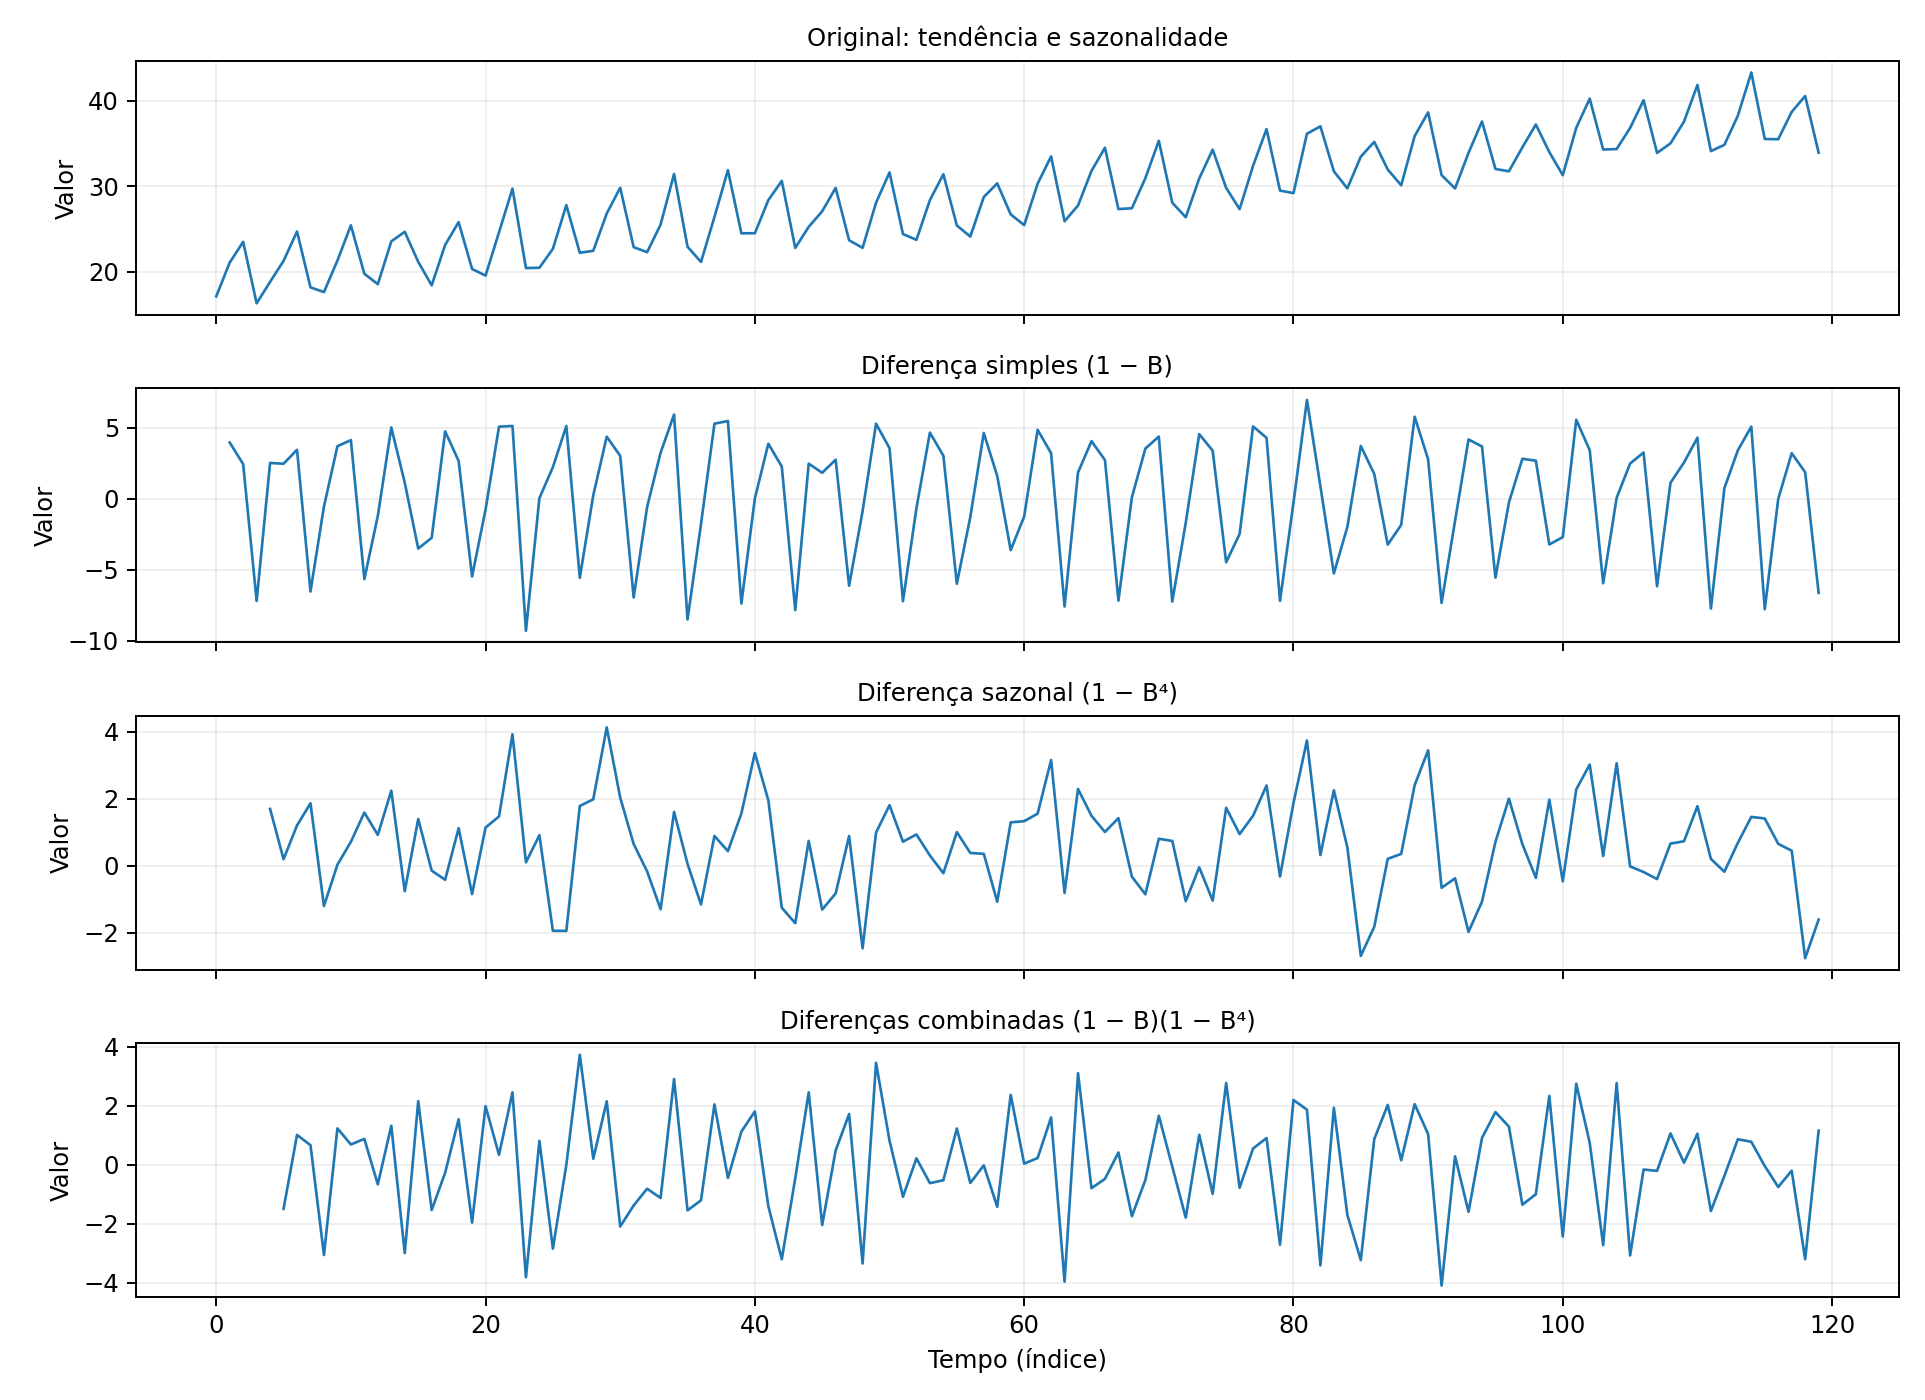

*Figura 1 — Série sintética com tendência linear e sazonalidade trimestral fixa, seguida de transformações simples, sazonal e combinada. A diferença simples não cancela o padrão sazonal fixo; a sazonal o elimina algebricamente, mas introduz ruído diferenciado na defasagem 4. A transformação combinada pode ser redundante para estacionariedade neste modelo.*

**Resultados conferidos ao executar o código:** no exemplo exato, a diferença sazonal retorna oito valores iguais a 2 e a combinação retorna sete zeros; as operações nas duas ordens fornecem o mesmo vetor. Na simulação, cada transformação possui os comprimentos esperados: 119, 116 e 115 observações. Os resultados visuais variam com a semente; a interpretação teórica não depende da realização escolhida.

### 8. Comparação com dados reais e limitações

Em aplicações meteorológicas, o período sazonal depende da frequência dos dados. Uma série mensal de precipitação total pode apresentar variação anual com $s=12$, mas a diferença $Z_t-Z_{t-12}$ **não** representa a variação diária de chuva. Valores ausentes não devem ser tratados automaticamente como precipitação zero, e uma sequência com meses faltantes exige reconstrução apropriada do calendário antes de comparar defasagens.

A diferença sazonal também não garante estacionariedade: mudanças de variância, mudanças de período, sazonalidade evolutiva, quebras de regime e séries com vários períodos podem permanecer problemáticas. Avaliações gráficas, modelagem dos componentes, estudo de autocovariâncias e testes formais posteriores fornecem evidências complementares, não provas absolutas.

Em tarefas de previsão, operações centradas que usem valores futuros não podem ser aplicadas indiscriminadamente durante o treinamento. As diferenças retrospectivas $Z_t-Z_{t-s}$ utilizam apenas o presente e o passado, mas a reconstrução do nível futuro depende de observações de referência corretamente disponíveis na origem da previsão.

### 9. Exercícios

**1. Cálculo manual.** Para $s=3$ e $z=(4,8,6,5,9,7,7,11,9)$, calcule a diferença sazonal e indique quantos termos restam.

**2. Distinção de operadores.** Desenvolva $(1-B)^2Z_t$ e $(1-B^2)Z_t$. Por que não representam a mesma transformação?

**3. Prova algébrica.** Demonstre para um $s$ genérico que $(1-B)(1-B^s)=(1-B^s)(1-B)$.

**4. Derivação estatística.** Para $Z_t=\alpha+\beta t+S_t+\varepsilon_t$ com $S_t=S_{t-s}$ e erros não correlacionados de variância $\sigma^2$, deduza a média, a variância e a autocovariância na defasagem $s$ de $\Delta_sZ_t$.

**5. Programação conceitual.** Descreva um algoritmo com `for` que receba uma lista e um período $s$, calcule as diferenças válidas sem inserir zeros e devolva um vetor de comprimento $N-s$. Só depois implemente e compare com as fatias do NumPy.

**6. Interpretação.** Por que a diferença combinada pode ser desnecessária quando a diferença sazonal já produz um processo fracamente estacionário?

**7. Dados meteorológicos.** Uma estação possui precipitação mensal em janeiro, fevereiro, março e maio, mas não em abril. Explique por que subtrair o valor da 12ª linha anterior não representa necessariamente a diferença para o mesmo mês do ano precedente.

**Conferência selecionada do exercício 1:** as seis diferenças sazonais são $(1,1,1,2,2,2)$.

### 10. Síntese

A diferença sazonal $\Delta_s=(1-B^s)$ compara instantes separados por $s$ períodos de observação. A combinação com a primeira diferença é $\Delta\Delta_s=(1-B)(1-B^s)$; sua expansão envolve quatro termos. Ambas as operações mudam o significado dos dados e sua dependência temporal. A escolha deve responder a um modelo e a uma questão estatística, não a uma regra automática baseada apenas na aparência dos gráficos.

### Referências utilizadas e escopo

- MORETTIN, Pedro A.; TOLOI, Clélia M. C. *Análise de Séries Temporais: Modelos Lineares Univariados*. Volume 1. 3. ed. São Paulo: Blucher, 2018. §§1.4 e 5.3.1, páginas impressas 6 e 143, conferidas visualmente. O capítulo 10 consta do sumário como tratamento de modelos sazonais; não foi usado aqui para atribuição de fórmulas específicas sem conferência adicional.
- *Mapeamento de conteúdos para Iniciação Científica: Séries Temporais*, aula “Aplicação de Diferenças”, com referência à diferença sazonal $Z_t-Z_{t-s}$, e aula sobre modelos SARIMA, disponíveis no arquivo do projeto.

**Nota editorial:** o aprofundamento de raízes unitárias, integração de ordem $d$, diferenças sazonais estocásticas e testes ADF/KPSS será tratado em seções posteriores. Não os pressupomos nesta seção.